In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from scipy.stats import skew, kurtosis

ERROR! Session/line number was not unique in database. History logging moved to new session 200


In [4]:
df = pd.read_csv(r'ecommerce_customer_behavior_1200.csv')
print(df.head())

  customer_id  age  gender       city membership  monthly_income_inr  \
0    CUST0001   34  Female  Bengaluru       Gold               57460   
1    CUST0002   22  Female      Delhi    Regular               54941   
2    CUST0003   38  Female       Pune       Gold               12000   
3    CUST0004   39  Female      Delhi     Silver               34777   
4    CUST0005   18    Male  Ahmedabad    Regular               51034   

   orders_last_3_months  avg_order_value_inr  monthly_spend_inr  discount_pct  \
0                     6                 2451               5497          28.9   
1                     1                 1011                386           9.5   
2                     2                 2931               2310          21.4   
3                     4                 1282               1504           5.5   
4                     1                 1220                397           9.9   

   delivery_days  satisfaction_score  website_minutes  returns_count  \
0       

## An e-commerce company wants to understand its customers, identify spending patterns, analyse unusual transactions and understand customer satisfaction.

In [5]:
print("Shape:", df.shape)
print("\nColumns")
print(df.columns)
print("\nDatatypes")
print(df.dtypes)
print("\nDataset Information")
df.info()
print("\nStatistical Summary")
df.describe()

Shape: (1200, 15)

Columns
Index(['customer_id', 'age', 'gender', 'city', 'membership',
       'monthly_income_inr', 'orders_last_3_months', 'avg_order_value_inr',
       'monthly_spend_inr', 'discount_pct', 'delivery_days',
       'satisfaction_score', 'website_minutes', 'returns_count',
       'payment_method'],
      dtype='str')

Datatypes
customer_id                 str
age                       int64
gender                      str
city                        str
membership                  str
monthly_income_inr        int64
orders_last_3_months      int64
avg_order_value_inr       int64
monthly_spend_inr         int64
discount_pct            float64
delivery_days           float64
satisfaction_score        int64
website_minutes         float64
returns_count             int64
payment_method              str
dtype: object

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column                Non-Null Count  

,age,monthly_income_inr,orders_last_3_months,avg_order_value_inr,monthly_spend_inr,discount_pct,delivery_days,satisfaction_score,website_minutes,returns_count
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,31.104167,52628.760833,4.070833,1534.785000,2310.730000,15.827750,3.345417,7.947500,21.944750,0.457500
std,8.275287,18716.742380,2.591926,845.096889,2403.883941,9.095451,1.270633,1.349541,15.284839,0.649522
min,18.000000,12000.000000,0.000000,315.000000,0.000000,0.600000,1.000000,3.000000,2.600000,0.000000
25%,25.000000,39690.750000,2.000000,978.000000,755.750000,8.675000,2.400000,7.000000,11.700000,0.000000
50%,31.000000,52596.000000,4.000000,1316.000000,1505.000000,14.600000,3.300000,8.000000,17.800000,0.000000
75%,37.000000,65028.000000,5.000000,1869.000000,2911.500000,21.500000,4.200000,9.000000,27.625000,1.000000
max,60.000000,113584.000000,15.000000,7985.000000,18194.000000,45.400000,7.600000,10.000000,127.300000,4.000000


Categorical and numerical columns

In [12]:
categorical_columns = ["gender","city","membership","payment_method"]

In [13]:
numerical_columns = ["age","monthly_income_inr", "orders_last_3_months", "avg_order_value_inr", "monthly_spend_inr","discount_pct", "delivery_days", "satisfaction_score", "website_minutes", "returns_count"]

types of sampling

In [18]:
# random sampling
sample = df.sample(n=200, random_state=42)
print(sample.shape)
sample.head()

(200, 15)


,customer_id,age,gender,city,membership,monthly_income_inr,orders_last_3_months,avg_order_value_inr,monthly_spend_inr,discount_pct,delivery_days,satisfaction_score,website_minutes,returns_count,payment_method
1178,CUST1179,34,Female,Bengaluru,Regular,62945,5,788,1427,19.2,3.8,8,2.6,1,Debit Card
865,CUST0866,38,Female,Pune,Regular,31958,5,861,1664,10.2,3.2,8,35.8,0,UPI
101,CUST0102,43,Male,Pune,Silver,25816,8,1670,5023,16.8,5.9,7,15.1,0,UPI
439,CUST0440,35,Male,Mumbai,Regular,61404,5,2159,3602,30.8,2.0,9,11.7,1,Net Banking
58,CUST0059,23,Female,Hyderabad,Gold,35850,8,2126,5665,20.4,1.9,9,119.9,2,UPI


In [22]:
# systematic sampling
system_sam = df.iloc[::10]
print(system_sam.shape)

(120, 15)


In [26]:
# stratefied sampling
strat_sam = df.groupby("membership", group_keys=False).sample(frac=0.2, random_state=42)
print(strat_sam["membership"].value_counts())

membership
Regular     121
Silver       60
Gold         42
Platinum     17
Name: count, dtype: int64


central tendency

In [27]:
print("how much does an average customer spend?",df["monthly_spend_inr"].mean())

how much does an average customer spend? 2310.73


In [30]:
print("What is the spending level of the typical middle customer?",df["monthly_spend_inr"].median())

What is the spending level of the typical middle customer? 1505.0


In [36]:
print("mode",df["payment_method"].mode()[0])

mode UPI


In [37]:
print("A customer who placed 10 orders should contribute more to the calculation than a customer who placed only 1 order.")
(df["avg_order_value_inr"] * df["orders_last_3_months"]).sum()/df["orders_last_3_months"].sum()

A customer who placed 10 orders should contribute more to the calculation than a customer who placed only 1 order.


np.float64(1691.8702149437052)

range

In [38]:
print("Range of monthly spend", df["monthly_spend_inr"].max() - df["monthly_spend_inr"].min())

Range of monthly spend 18194


Variance and std dev

In [39]:
print("population var",df["monthly_spend_inr"].var(ddof=0))
print("sample var",df["monthly_spend_inr"].var(ddof=1))

population var 5773842.4521
sample var 5778658.0004336955


In [41]:
print("population std",df["monthly_spend_inr"].std(ddof=0))
print("sample std",df["monthly_spend_inr"].std(ddof=1))

population std 2402.8821136501892
sample std 2403.883940716293


percentiles and quantiles

In [43]:
print("What is the spending threshold for the top 10% of customers?", df["monthly_spend_inr"].quantile(0.1))

What is the spending threshold for the top 10% of customers? 371.40000000000003


In [44]:
print(df["monthly_spend_inr"].quantile(0.25))
print(df["monthly_spend_inr"].quantile(0.5))
print(df["monthly_spend_inr"].quantile(0.75))

755.75
1505.0
2911.5


IQR

In [47]:
Q1 = df["monthly_spend_inr"].quantile(0.25)
Q3 = df["monthly_spend_inr"].quantile(0.75)

IQR = Q3 - Q1

lb = Q1-1.5*IQR
ub = Q3+1.5*IQR

print("IQR:", IQR)
print("Lower Limit:", lb)
print("Upper Limit:", ub)

IQR: 2155.75
Lower Limit: -2477.875
Upper Limit: 6145.125


In [51]:
outliers = df[
    (df["monthly_spend_inr"] < lb) | (df["monthly_spend_inr"] > ub)
]
print("Number of potential outliers:", len(outliers))

outliers[[
    "customer_id",
    "monthly_spend_inr",
    "membership"
]].head(10)

Number of potential outliers: 90


,customer_id,monthly_spend_inr,membership
9,CUST0010,6458,Gold
26,CUST0027,7135,Gold
38,CUST0039,9080,Gold
76,CUST0077,7809,Platinum
78,CUST0079,10112,Gold
82,CUST0083,18194,Platinum
90,CUST0091,6811,Platinum
94,CUST0095,8899,Platinum
102,CUST0103,11209,Gold
117,CUST0118,6355,Gold


In [52]:
s = skew(df["monthly_spend_inr"].dropna())
print(s)

2.2949098678406075


In [53]:
k = kurtosis(df["monthly_spend_inr"].dropna())
print(k)

6.771618837899684


frequency ditribution

In [59]:
bins = [17, 25, 35, 45, 55, 65]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65"]

df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels)
age_frequency = df["age_group"].value_counts().sort_index()

print(age_frequency)

age_group
18-25    322
26-35    545
36-45    273
46-55     56
56-65      4
Name: count, dtype: int64


In [63]:
relative_frequency = age_frequency / len(df)

percentage_frequency = relative_frequency * 100
print(percentage_frequency)

age_group
18-25    26.833333
26-35    45.416667
36-45    22.750000
46-55     4.666667
56-65     0.333333
Name: count, dtype: float64


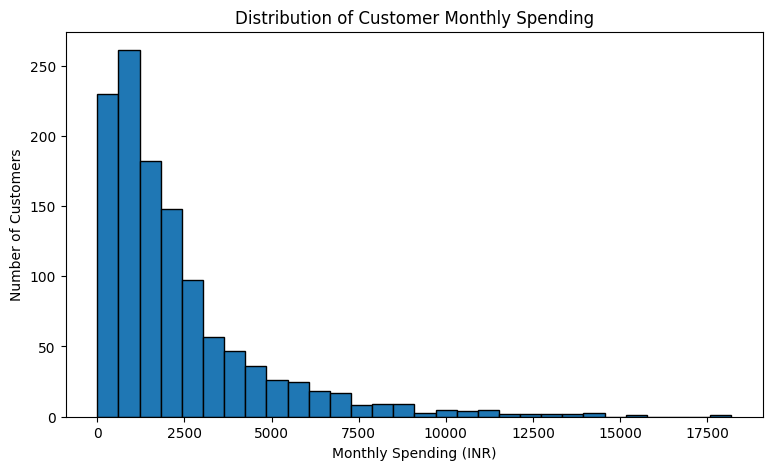

In [64]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["monthly_spend_inr"],
    bins=30,
    edgecolor="black"
)

plt.xlabel("Monthly Spending (INR)")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Monthly Spending")

plt.show()

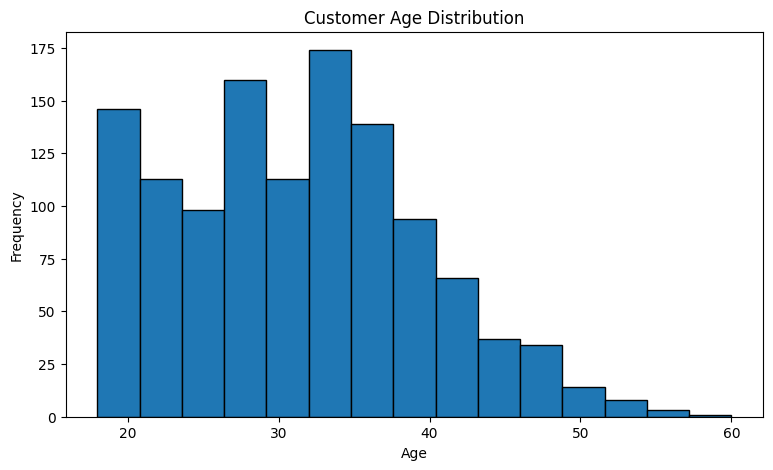

In [65]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["age"],
    bins=15,
    edgecolor="black"
)

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Customer Age Distribution")

plt.show()

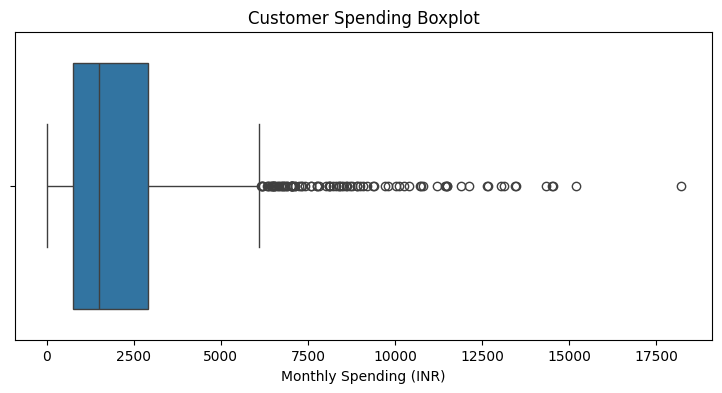

In [66]:
plt.figure(figsize=(9, 4))

sns.boxplot(
    x=df["monthly_spend_inr"]
)

plt.xlabel("Monthly Spending (INR)")
plt.title("Customer Spending Boxplot")

plt.show()

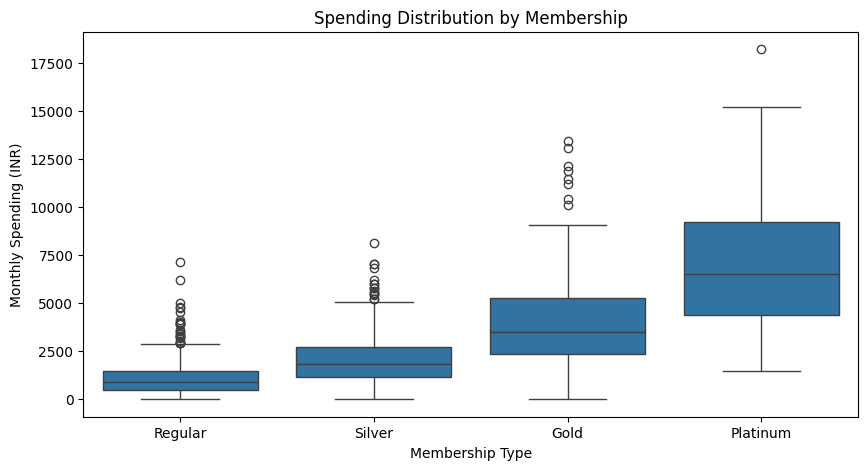

In [67]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="membership",
    y="monthly_spend_inr",
    order=["Regular", "Silver", "Gold", "Platinum"]
)

plt.xlabel("Membership Type")
plt.ylabel("Monthly Spending (INR)")
plt.title("Spending Distribution by Membership")

plt.show()